# Exploratory Data Analysis: Public Transport Delays with Weather & Events

This notebook walks through the data step by step. It explains **what** we look at and **why**, so it can be used for a report or viva.

> ⚠️ **The dataset is synthetic.** It was created by `src/generate_data.py` using rules we chose (for example "storms add delay"). Any pattern found here exists because the generator put it there. These are **not** real-world transport statistics.

Run `python run_pipeline.py` from the project folder first, so the cleaned data exists.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats

sys.path.append(str(Path.cwd().parent / "src"))   # so we can import our own modules
import plots
from config import RAW_DATA, CLEAN_DATA, REPORTS_DIR

%matplotlib inline
pd.set_option("display.max_columns", 40)

## 1. Load the raw data and check its quality
Before analysing anything, we check the size of the data, the column types, missing values and duplicates.

In [2]:
raw = pd.read_csv(RAW_DATA, keep_default_na=False, na_values=[""])
print("Rows, columns:", raw.shape)
raw.head()

Rows, columns: (6030, 24)


,trip_id,date,time,transport_type,route_id,origin_station,destination_station,distance_km,scheduled_departure,scheduled_arrival,departure_delay_min,arrival_delay_min,weather_condition,temperature_c,humidity_pct,wind_speed_kmh,precipitation_mm,event_type,event_attendance,traffic_congestion_index,is_holiday,weekday,season,delayed
0,T02005,2023-01-01,06:10:00,Bus,Route_4,Station_38,Station_26,11.8,06:10:00,06:45:00,1,-3,Clear,3.0,45.4,10.5,0.0,No Event,0,0.88,1,Sunday,Winter,0
1,T04471,2023-01-01,07:38:00,Metro,Route_20,Station_12,Station_19,8.7,07:38:00,07:53:00,0,-3,Clear,5.3,NaN,10.5,0.0,No Event,0,0.59,1,Sunday,Winter,0
2,T05850,2023-01-01,08:16:00,Tram,Route_17,Station_47,Station_22,9.6,08:16:00,08:48:00,-2,-3,Clear,3.7,45.4,10.5,0.0,No Event,0,0.92,1,Sunday,Winter,0
3,T04452,2023-01-01,09:36:00,Bus,Route_8,Station_28,Station_43,14.5,09:36:00,10:20:00,4,2,Clear,3.2,45.4,10.5,0.0,No Event,0,0.00,1,Sunday,Winter,0
4,T01688,2023-01-01,09:38:00,Metro,Route_18,Station_41,Station_5,21.8,09:38:00,10:15:00,7,4,Clear,5.1,45.4,10.5,0.0,No Event,0,1.29,1,Sunday,Winter,0


In [3]:
print("Missing values per column (only columns with any):")
print(raw.isna().sum()[raw.isna().sum() > 0])
print("\nDuplicate trip_ids:", raw["trip_id"].duplicated().sum())

Missing values per column (only columns with any):
temperature_c     86
humidity_pct      88
wind_speed_kmh    93
dtype: int64

Duplicate trip_ids: 30


The raw file has a few missing weather readings and some duplicated trips. `src/preprocess.py` fixes these:
- duplicates are dropped,
- missing weather values are filled with the **median for the same weather condition** (a rainy day's humidity is filled from other rainy days, not from sunny ones),
- new time features are added: `hour`, `month`, `day_of_week`, `is_weekend`, `is_peak_hour`, `scheduled_duration_min`.

In [4]:
df = pd.read_csv(CLEAN_DATA, keep_default_na=False, na_values=[""])
print("Clean rows:", len(df), "| missing values left:", int(df.isna().sum().sum()))
df.describe().T.round(2)

Clean rows: 6000 | missing values left: 0


,count,mean,std,min,25%,50%,75%,max
distance_km,6000.0,21.81,20.92,6.0,8.70,11.80,21.80,78.2
departure_delay_min,6000.0,2.98,3.70,-2.0,0.00,2.00,5.00,41.0
arrival_delay_min,6000.0,7.39,8.01,-3.0,2.00,6.00,11.00,102.0
temperature_c,6000.0,14.66,9.90,-11.2,7.68,14.20,21.70,38.8
humidity_pct,6000.0,67.65,15.92,29.5,55.60,65.30,79.60,100.0
wind_speed_kmh,6000.0,12.84,10.03,0.5,6.20,10.30,16.50,60.4
precipitation_mm,6000.0,4.45,8.68,0.0,0.00,0.20,4.60,45.0
event_attendance,6000.0,2089.20,7347.33,0.0,0.00,0.00,0.00,53044.0
traffic_congestion_index,6000.0,4.05,1.91,0.0,2.59,3.89,5.41,10.0
is_holiday,6000.0,0.03,0.17,0.0,0.00,0.00,0.00,1.0


## 2. The target: how late are trips?
We have two targets:
- `arrival_delay_min`: minutes late (negative = early), used for **regression**
- `delayed`: 1 if more than 5 minutes late, used for **classification**

Mean delay: 7.39 min | median: 6 min
Share of delayed trips: 53.2%


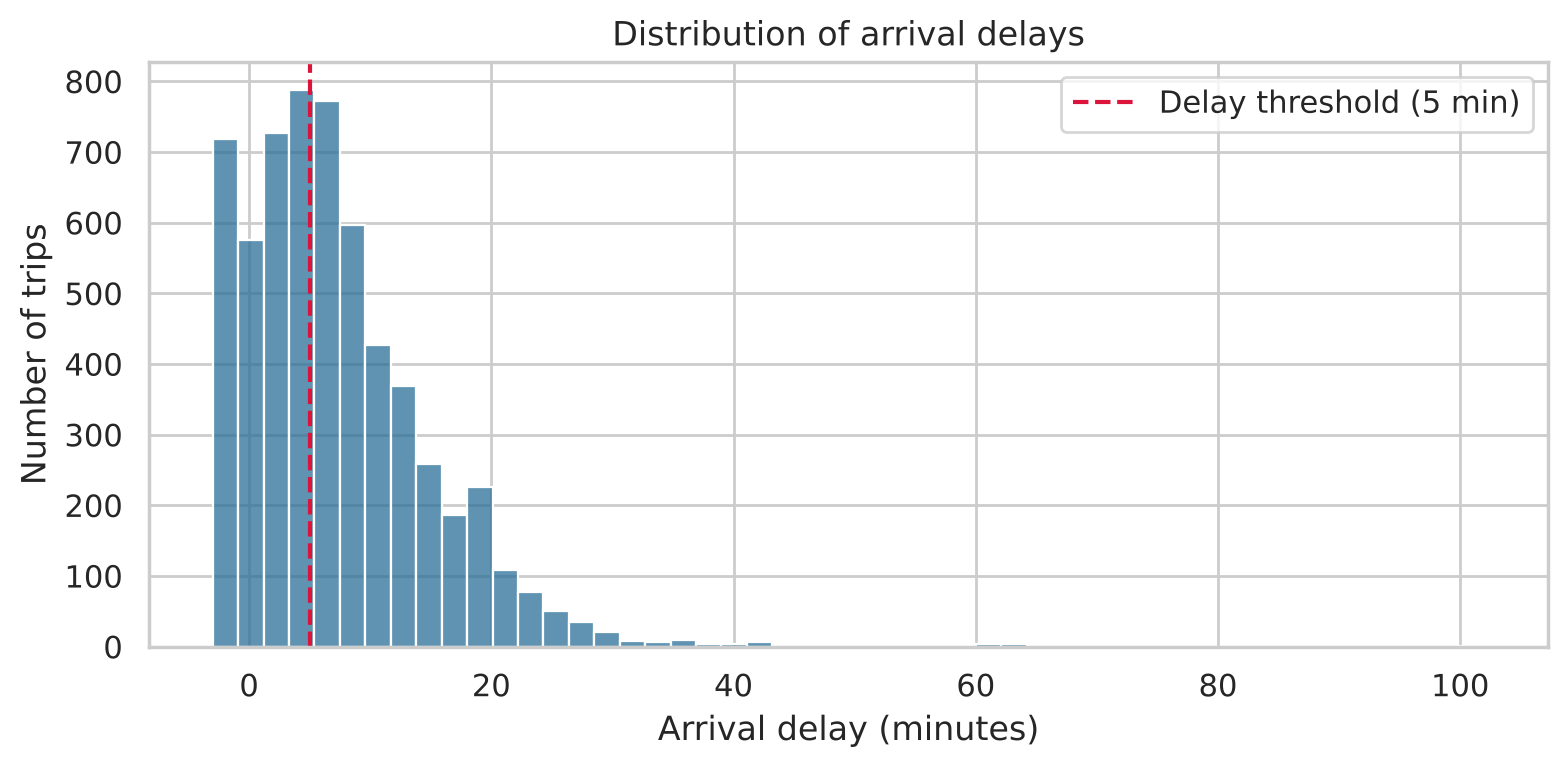

In [5]:
print(f"Mean delay: {df['arrival_delay_min'].mean():.2f} min | median: {df['arrival_delay_min'].median():.0f} min")
print(f"Share of delayed trips: {df['delayed'].mean():.1%}")
plots.delay_distribution(df);

The distribution is **right-skewed**: most trips are a few minutes late, but a small number are very late (the generator adds rare "incidents"). The two classes are roughly balanced, so accuracy is a fair metric, but we also report F1 and ROC-AUC.

## 3. Transport type and route

In [6]:
df.groupby("transport_type")["arrival_delay_min"].agg(["count", "mean", "median"]).round(2).sort_values("mean")

,count,mean,median
transport_type,,,
Metro,819,3.21,2.0
Tram,1233,6.16,5.0
Train,1448,7.56,6.0
Bus,2500,9.27,8.0


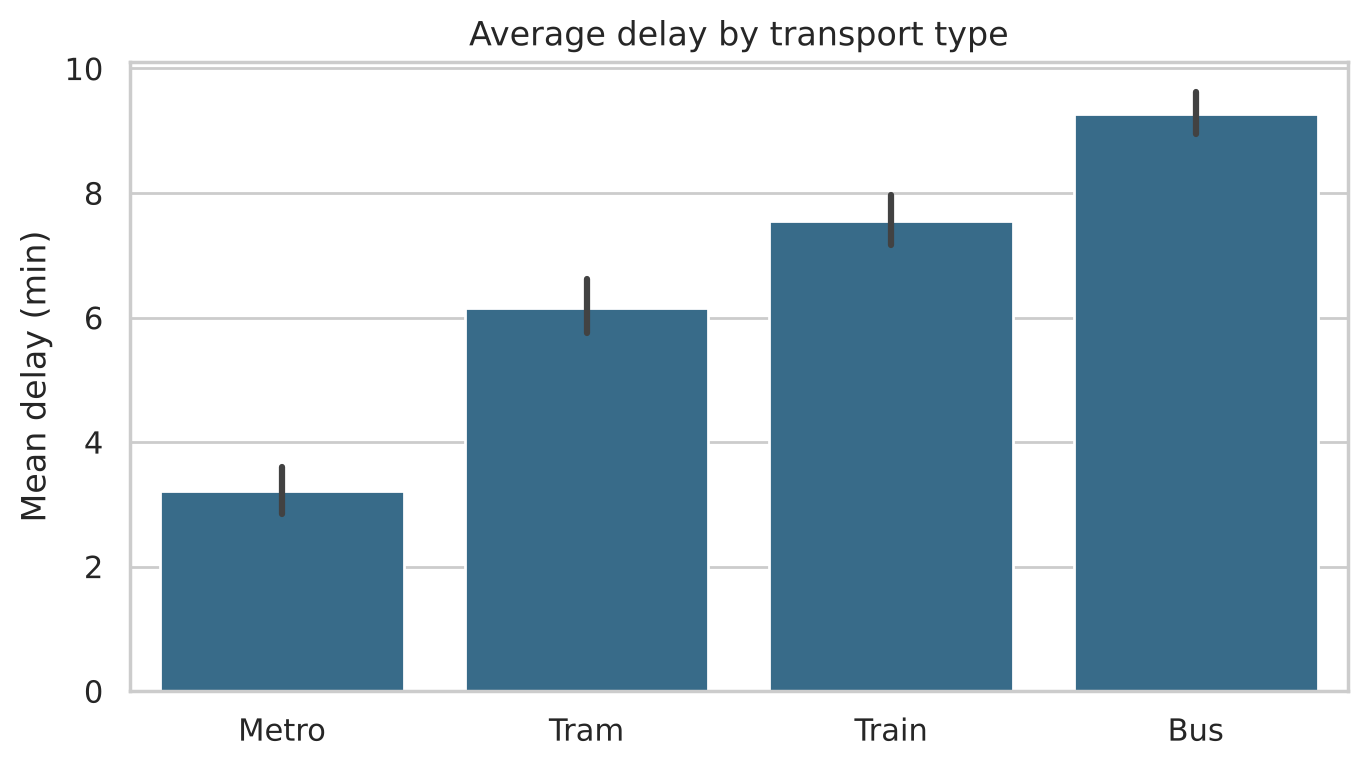

In [7]:
plots.delay_by_transport(df);

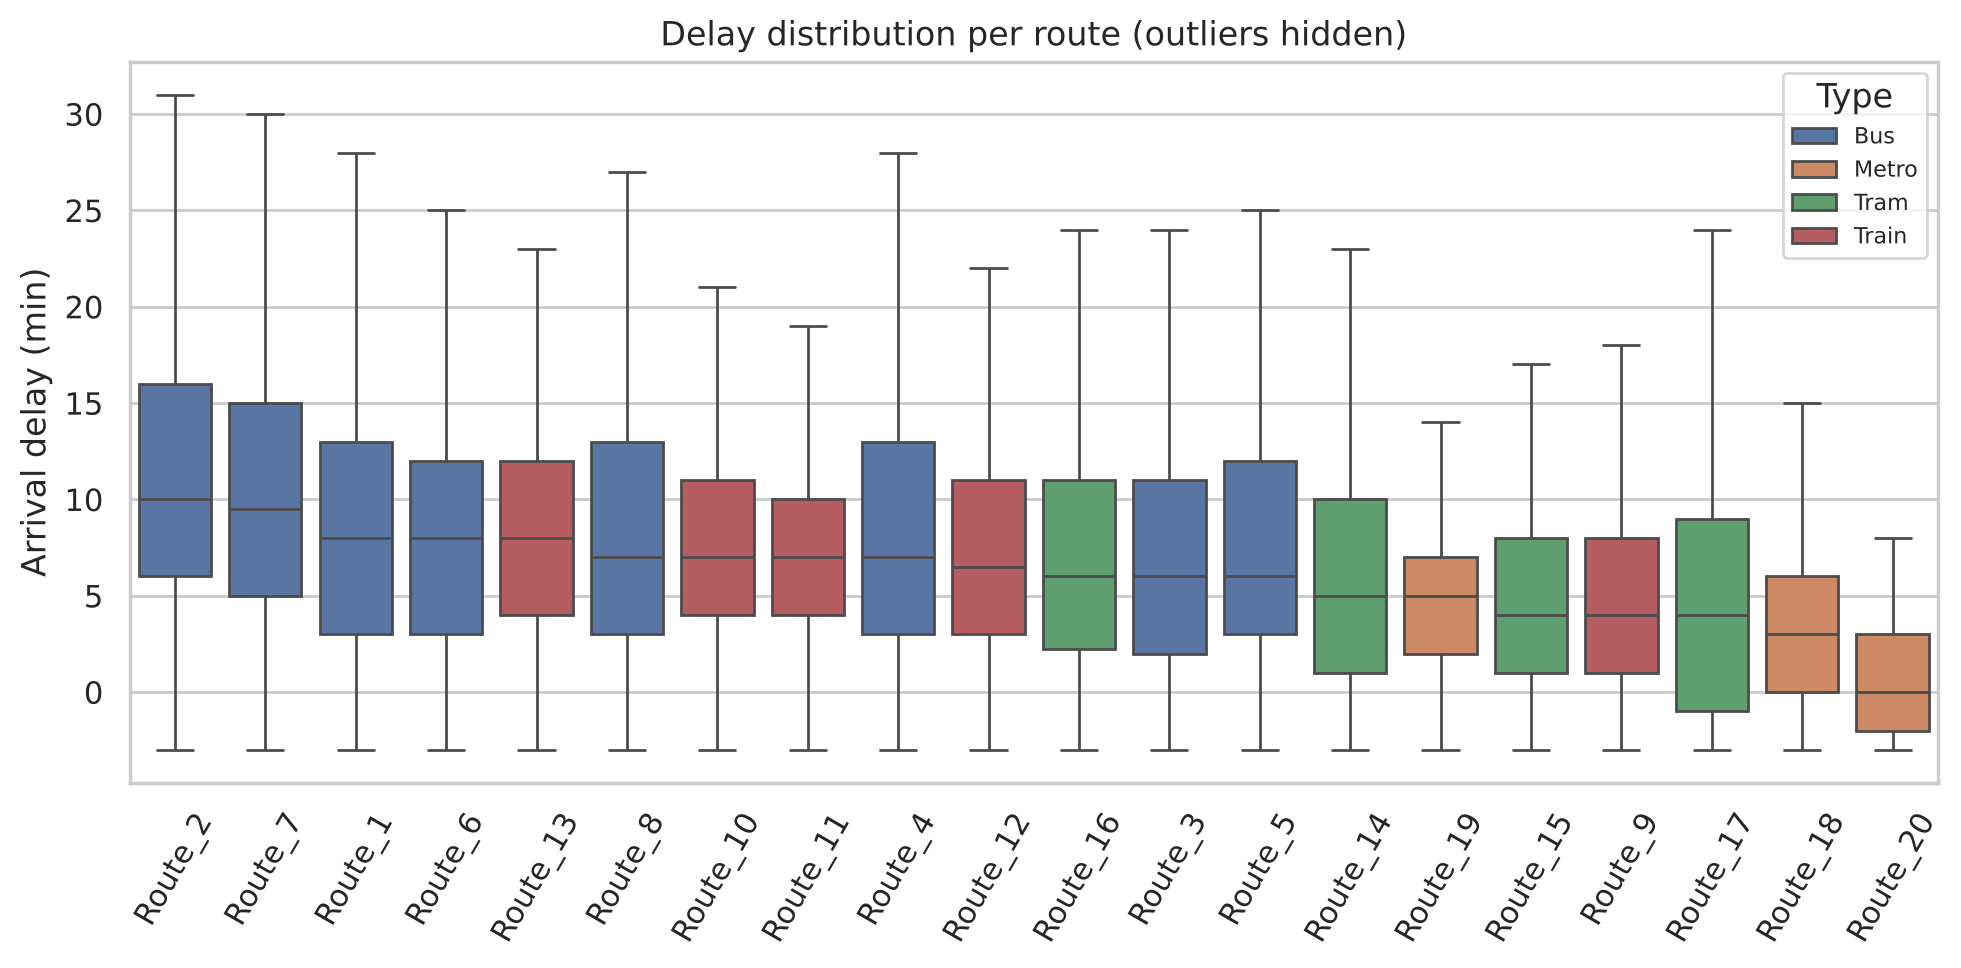

In [8]:
plots.delay_by_route(df);

Metro has the lowest delays and buses the highest. That matches the generator's assumption that metro runs underground (little effect from weather or road traffic) while buses share the roads. Routes of the same type also differ, because each route was given a small random "personality".

## 4. Weather impact (Objective 1)

In [9]:
weather = df.groupby("weather_condition")["arrival_delay_min"].agg(["count", "mean"]).round(2)
weather.sort_values("mean")

,count,mean
weather_condition,,
Clear,2234,4.42
Cloudy,1336,5.19
Fog,467,7.85
Rain,769,8.07
Snow,249,12.59
Heavy Rain,593,13.50
Storm,352,18.52


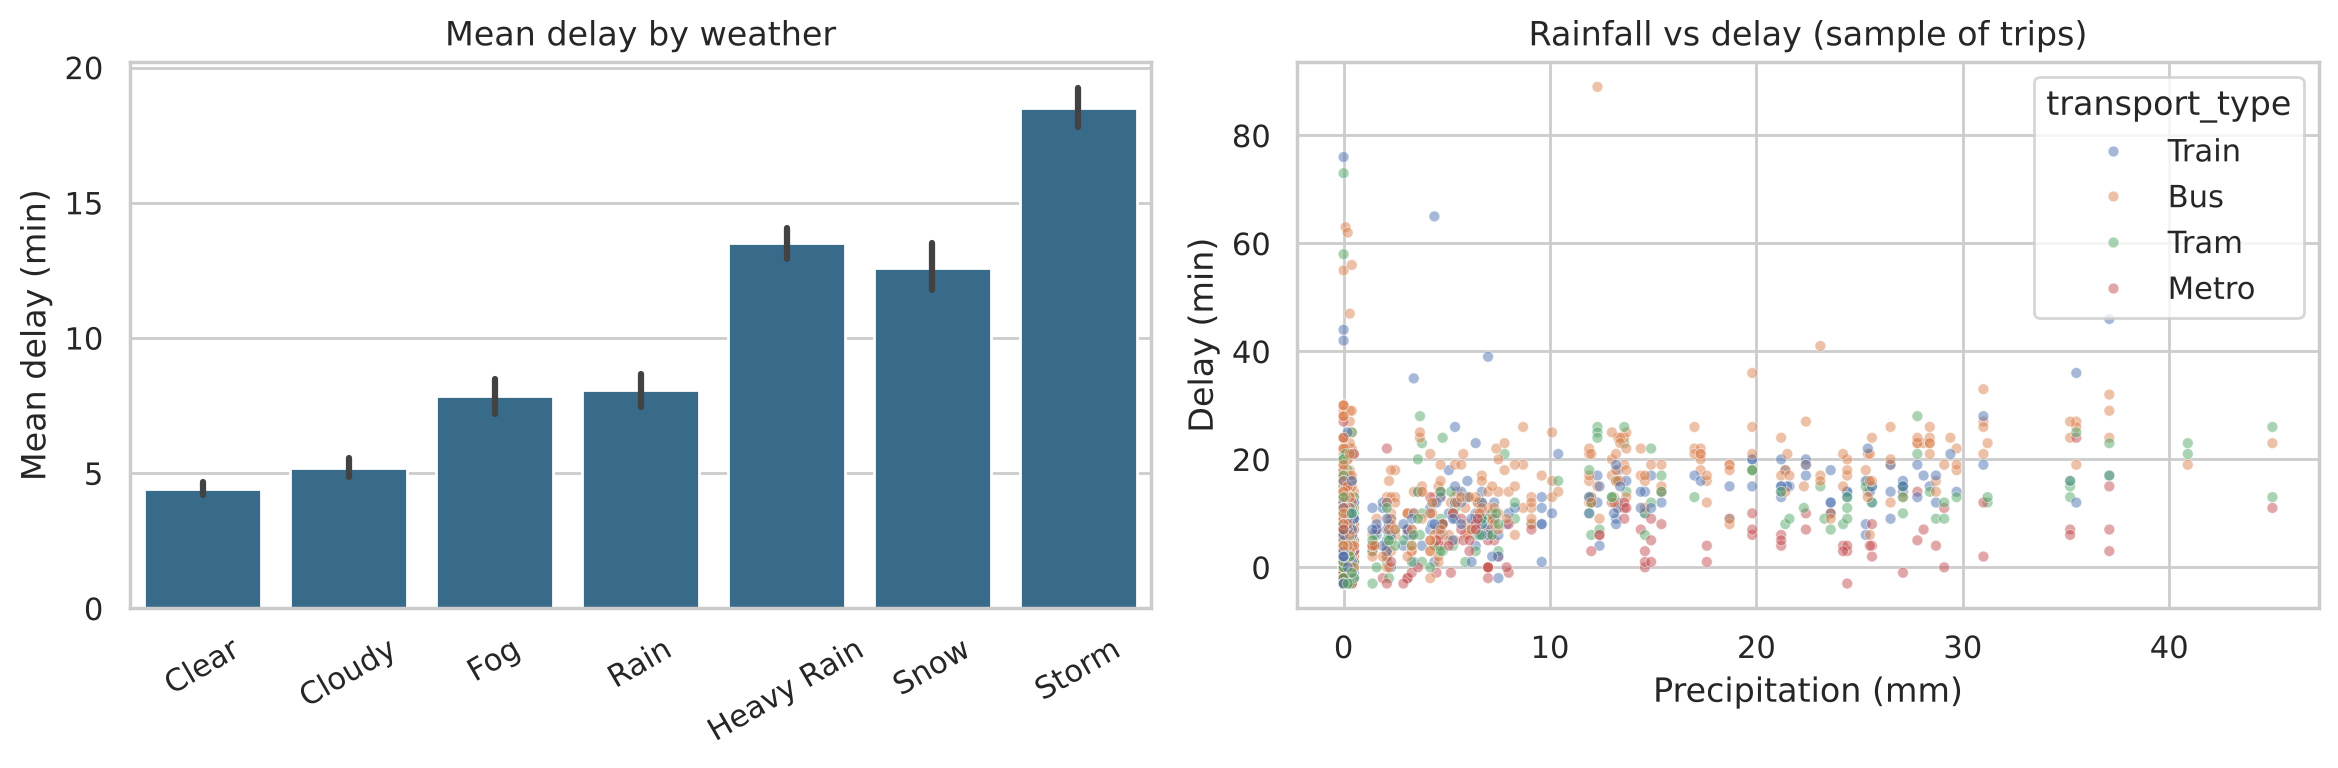

In [10]:
plots.delay_by_weather(df);

Is the difference between clear and stormy days real, or could it be chance? A **Welch t-test** compares the two group means without assuming equal variances. A tiny p-value means the difference is very unlikely to be random noise *in this dataset*.

In [11]:
clear = df.loc[df["weather_condition"] == "Clear", "arrival_delay_min"]
bad = df.loc[df["weather_condition"].isin(["Heavy Rain", "Snow", "Storm"]), "arrival_delay_min"]
t, p = stats.ttest_ind(bad, clear, equal_var=False)
print(f"Clear: {clear.mean():.2f} min (n={len(clear)}) | Heavy rain/snow/storm: {bad.mean():.2f} min (n={len(bad)})")
print(f"Welch t = {t:.1f}, p = {p:.2e}")

Clear: 4.42 min (n=2234) | Heavy rain/snow/storm: 14.79 min (n=1194)
Welch t = 40.5, p = 5.67e-265


## 5. City events (Objective 2)

In [12]:
df.groupby("event_type")["arrival_delay_min"].agg(["count", "mean"]).round(2).sort_values("mean")

,count,mean
event_type,,
No Event,5388,6.93
Protest,122,7.30
Festival,145,9.81
Parade,63,11.00
Concert,140,13.51
Sports,142,14.89


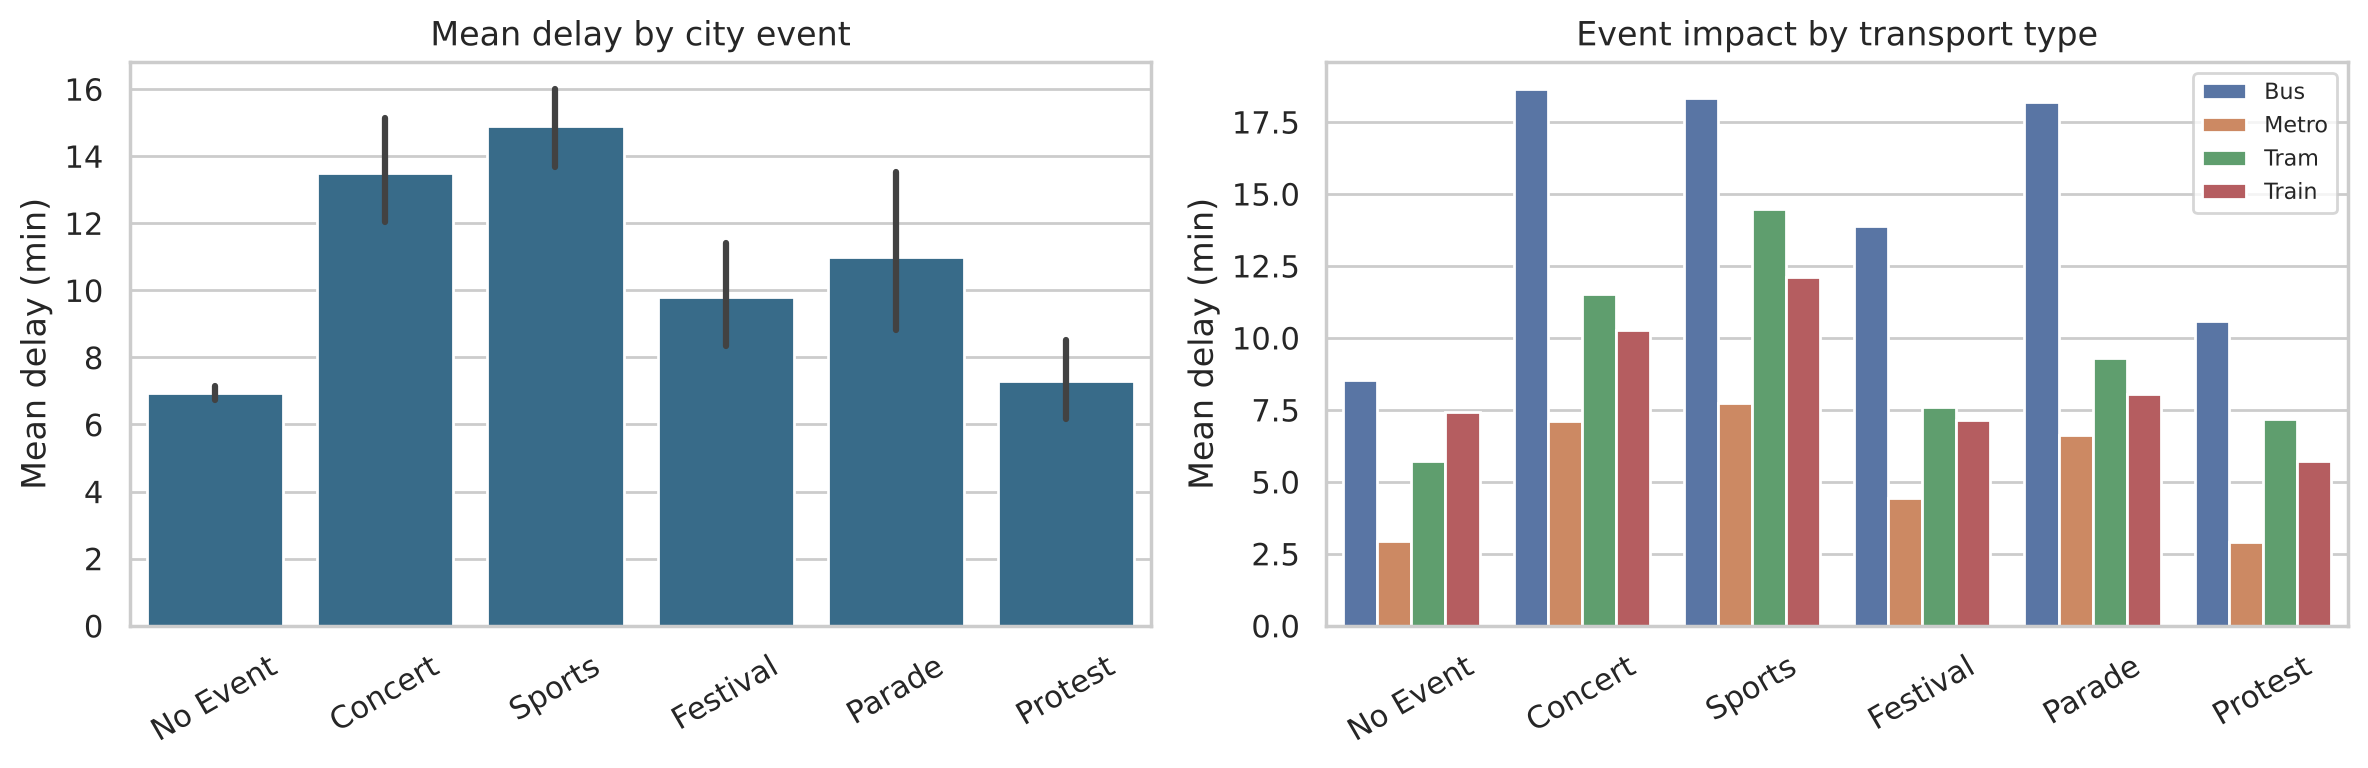

In [13]:
plots.delay_by_event(df);

In [14]:
ev = df.loc[df["event_type"] != "No Event", "arrival_delay_min"]
no_ev = df.loc[df["event_type"] == "No Event", "arrival_delay_min"]
t, p = stats.ttest_ind(ev, no_ev, equal_var=False)
print(f"With event: {ev.mean():.2f} min (n={len(ev)}) | no event: {no_ev.mean():.2f} min (n={len(no_ev)})")
print(f"Welch t = {t:.1f}, p = {p:.2e}")
print("Correlation between attendance and delay (event trips only):",
      round(df.loc[df['event_type'] != 'No Event', ['event_attendance', 'arrival_delay_min']].corr().iloc[0, 1], 3))

With event: 11.46 min (n=612) | no event: 6.93 min (n=5388)
Welch t = 12.2, p = 2.82e-31
Correlation between attendance and delay (event trips only): 0.428


Trips that run during an event are later on average, and bigger crowds go with bigger delays. Only about 10% of trips overlap an event, so these estimates are noisier than the weather ones.

## 6. Time patterns: peak hours and weekdays (Objective 3)

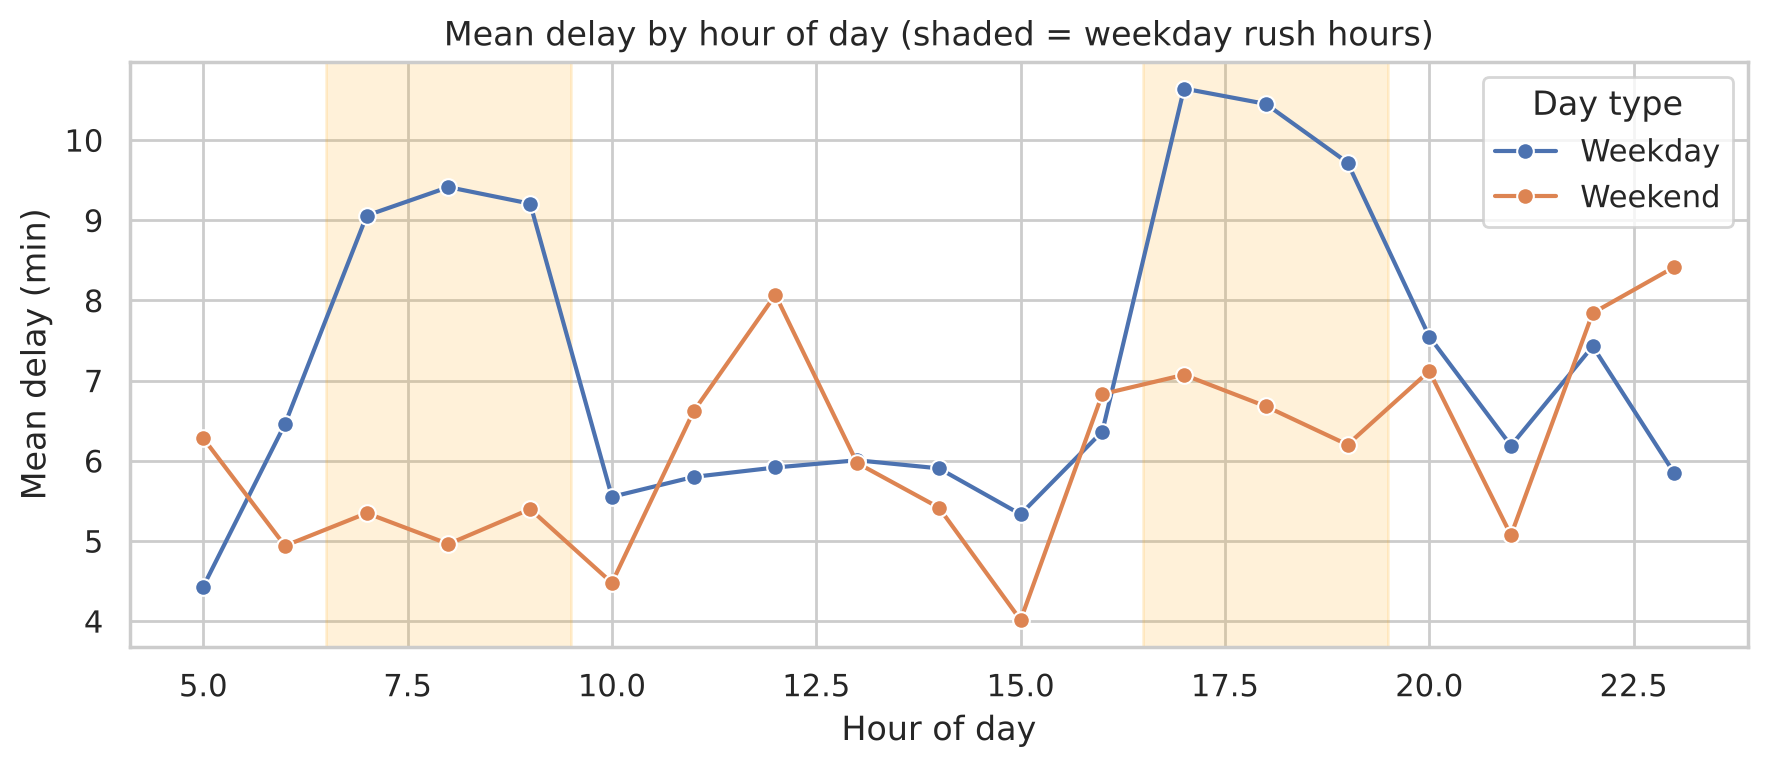

In [15]:
plots.delay_by_hour(df);

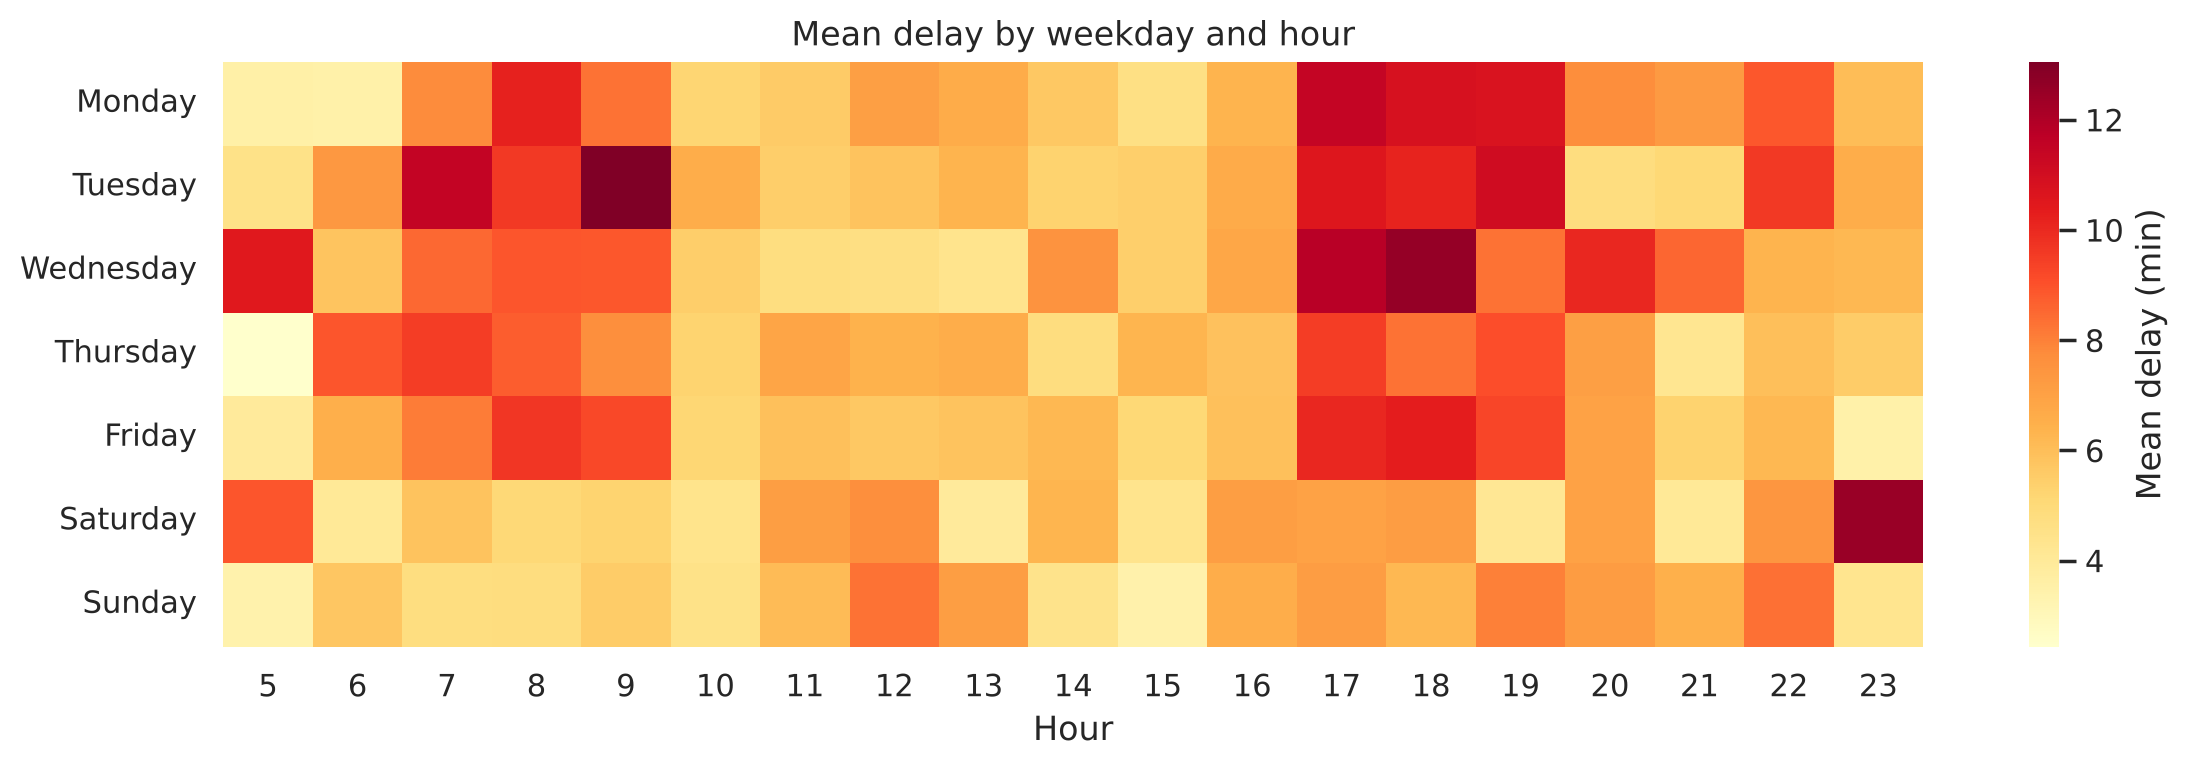

In [16]:
plots.hour_weekday_heatmap(df);

In [17]:
df.groupby(["is_peak_hour"])["arrival_delay_min"].agg(["count", "mean"]).round(2)

,count,mean
is_peak_hour,,
0,3923,6.02
1,2077,9.98


Weekday rush hours (7-9 am and 5-7 pm) stand out, while weekends stay flatter. The generator adds delay at peak times and more traffic congestion then.

## 7. How do the numeric features relate to each other?

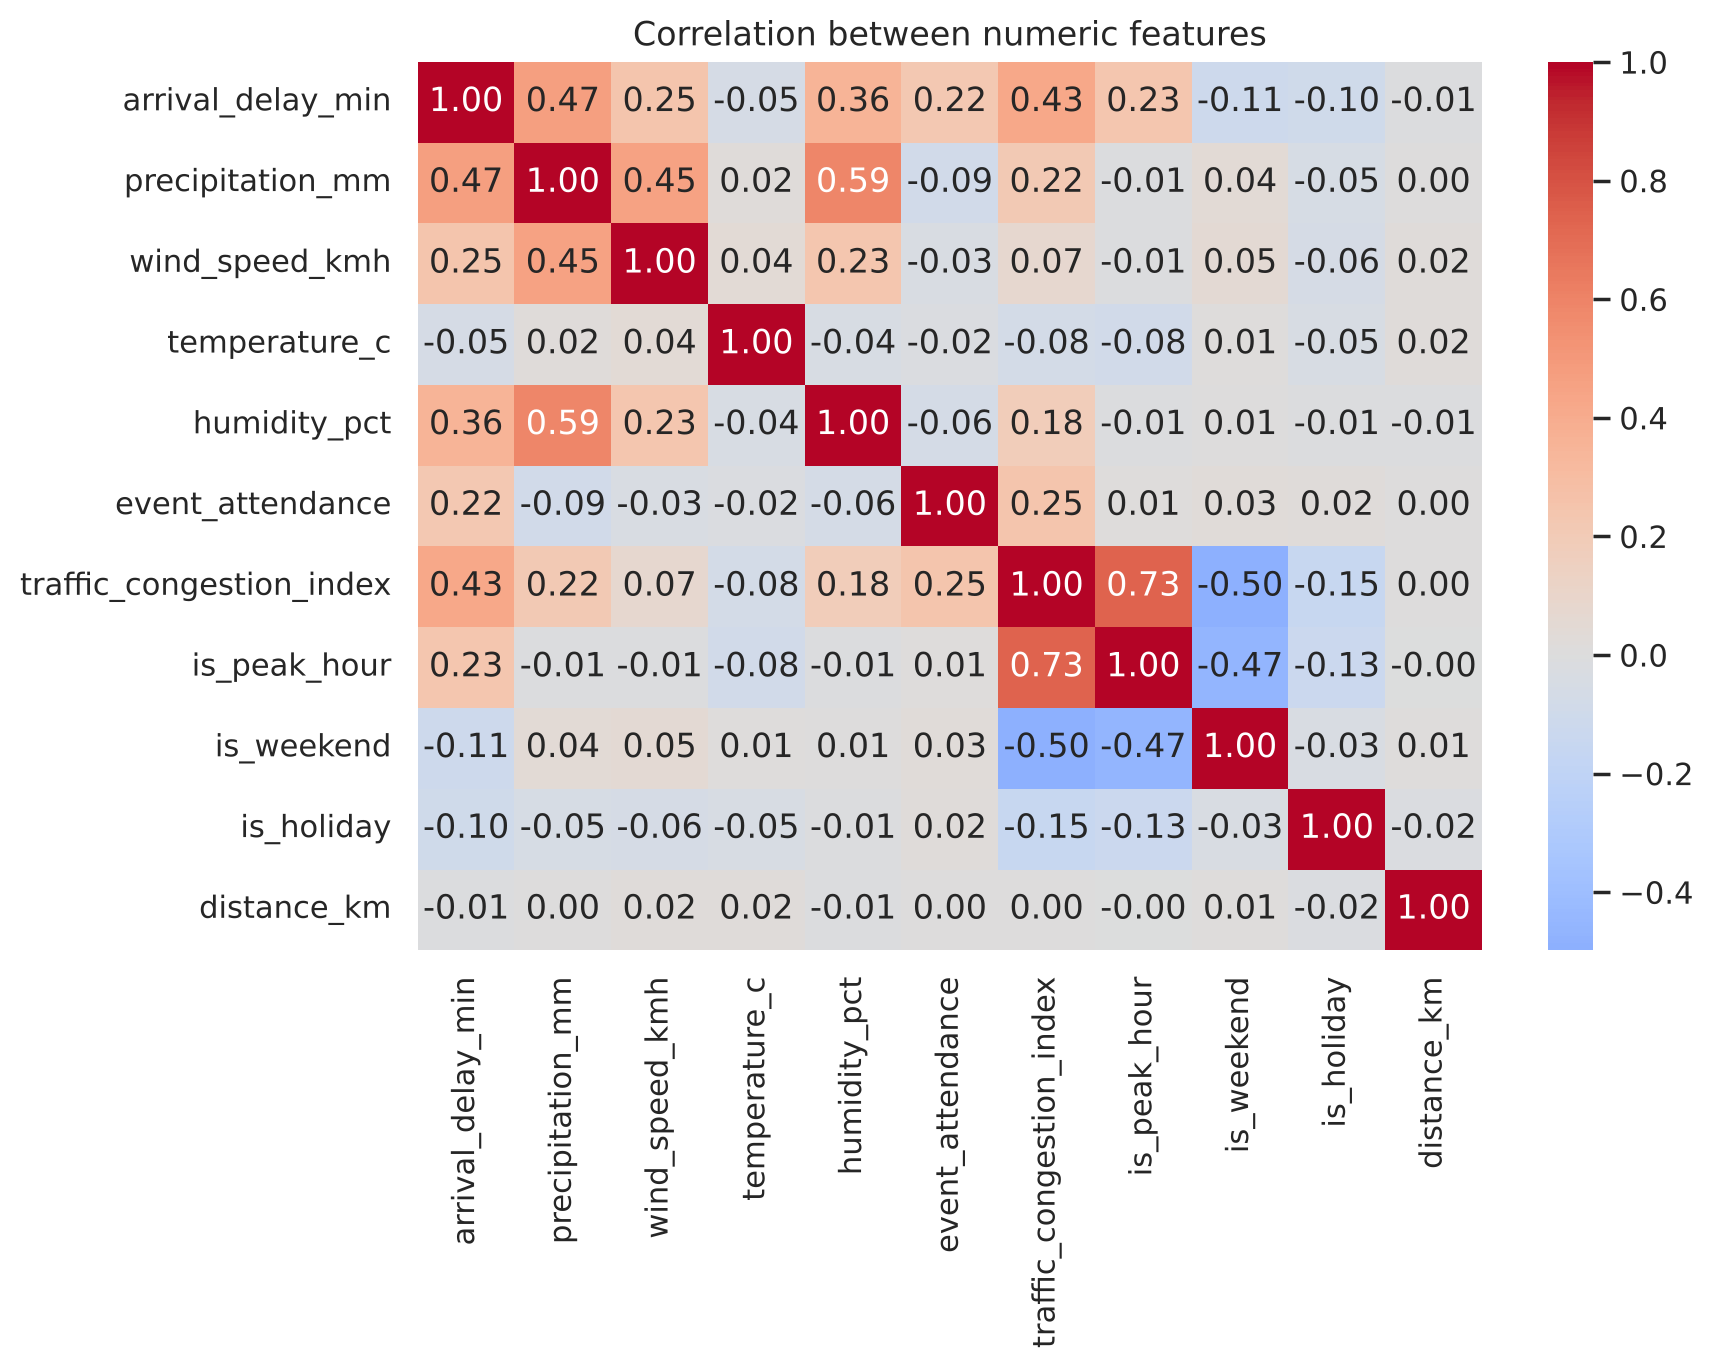

In [18]:
plots.correlation_heatmap(df);

Correlation only measures *straight-line* relationships between pairs of columns. Precipitation and congestion show the clearest links with delay. Features can still matter in combination even if their single correlation is small, which is why we also train models.

## 8. Link to the models
`src/train.py` trains 4 classifiers and 4 regressors. The table below is read straight from the saved results (not typed in by hand).

In [19]:
pd.read_csv(REPORTS_DIR / "metrics_classification.csv")

,model,"cv_f1 (train, 5-fold)",accuracy,precision,recall,f1,roc_auc
0,Gradient Boosting,0.8162,0.7925,0.8142,0.7900,0.8019,0.8756
1,Logistic Regression,0.8251,0.7867,0.7975,0.8025,0.8000,0.8683
2,Random Forest,0.8059,0.7917,0.8212,0.7774,0.7987,0.8688
3,Decision Tree,0.7630,0.7683,0.8297,0.7100,0.7652,0.8230


In [20]:
pd.read_csv(REPORTS_DIR / "metrics_regression.csv")

,model,"cv_mae (train, 5-fold)",mae,rmse,r2
0,Gradient Boosting,3.2618,3.3776,6.2648,0.4218
1,Linear Regression,3.3300,3.5479,6.3858,0.3992
2,Random Forest,3.3717,3.5677,6.4416,0.3887
3,Decision Tree,3.7962,3.8014,7.0169,0.2746


In [21]:
pd.read_csv(REPORTS_DIR / "feature_importance.csv").head(8)

,feature,importance
0,precipitation_mm,1.580045
1,transport_type,0.685560
2,traffic_congestion_index,0.544990
3,event_attendance,0.390350
4,weather_condition,0.206123
5,temperature_c,0.196472
6,month,0.187925
7,route_id,0.102658


## 9. Summary
- **Weather**: severe weather (heavy rain, snow, storms) is linked to the largest delays in this dataset.
- **Events**: trips during events are later on average, and more so for large crowds.
- **Time**: weekday rush hours have higher delays than the rest of the day.
- **Mode**: metro is the most reliable mode here, buses the least.
- **Models**: Gradient Boosting performed best, but simple linear models were close, because the generator mostly adds effects together.

**Limitation (again):** all of this describes a simulation. To make real-world claims you would need real timetable, GPS/arrival, weather and event data.